# Interpretasi SHAP

#Persiapan Library & File Terlibat

> Add blockquote



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
import os
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv("/content/drive/MyDrive/Fatma/DATA SIAP PAKAI/all_data_transformed.csv")

df_awal = df.sort_values('Tanggal')
print(df.head())




Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
   Tanggal  BI_Rate  Inflasi    kurs  Minyak_Mentah  Tingkat_Pengangguran  \
0  2010-01      6.5     0.84  9275.0          76.17                  7.49   
1  2010-02      6.5    -0.08  9348.0          73.75                  7.41   
2  2010-03      6.5    -0.14  9174.0          78.83                  7.36   
3  2010-04      6.5     0.15  9027.0          84.82                  7.32   
4  2010-05      6.5     0.29  9183.0          75.95                  7.28   

   Nilai_Uang_Beredar         IHSG  
0         206648099.0  2575.312988  
1          21120827.0  2587.448242  
2         211602354.0  2554.574463  
3         214323405.0  2829.885986  
4         223114433.0  2960.779785  


In [ ]:
#Cek Versi SHAP yang digunakan
print('SHAP Version::: ',shap.__version__)

SHAP Version:::  0.52.0


# Latih Model

In [ ]:

df = df_awal.copy()
#Membuat fitur lag
df['inflasi_lag12'] = df['Inflasi'].shift(12)
df['kurs_lag1'] = df['kurs'].shift(1)
df['ihsg_lag1'] = df['IHSG'].shift(1)
df['uang_beredar_lag1'] = df['Nilai_Uang_Beredar'].shift(1)
df['minyak_mentah_lag7'] = df['Minyak_Mentah'].shift(7)
df['BI_Rate_lag1'] = df['Minyak_Mentah'].shift(1)

#Menghapus Data Kosong
df = df.dropna().reset_index(drop=True)

#Menentukan Fitur dan Target
fitur = ['inflasi_lag12','kurs_lag1','ihsg_lag1','uang_beredar_lag1','minyak_mentah_lag7','BI_Rate_lag1']

X = df[fitur]
y = df['Inflasi']

#Membagi data trai dan test
split = int(len(df) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

#Melatih Model XGBoost
model = XGBRegressor(
    random_state=42
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

#Prediksi
y_pred = model.predict(X_test)

#Evaluasi Model
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

rmse = mean_squared_error(y_test, y_pred) ** 0.5
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
cor_cof = np.corrcoef(y_test,y_pred)[0,1]

print('RMSE :',rmse)
print('MAE : ',mae)
print('R2 :',r2)
print('Correlation Cofficient : ',cor_cof)


RMSE : 0.38274971685898446
MAE :  0.29987318869421464
R2 : 0.10518600303470438
Correlation Cofficient :  0.37453757551391914


## Folder Tempat Penyimpanan Hasil

In [ ]:
# Membuat folder Tempat Penyimpanan Hasil
folder = "/content/drive/MyDrive/Fatma/DATA SIAP PAKAI/Hasil_SHAP/Model 3  & BI/"
os.makedirs(folder, exist_ok=True)

## Hitung Nilai SHAP

In [ ]:
#Membuah Shap Explainer
explainer = shap.TreeExplainer(model)

#Hitung Niai Shap
shap_values = explainer.shap_values(X_test)
print("Jumlah data uji :", X_test.shape)
print("Ukuran SHAP :", shap_values.shape)

#Simpan Nilai Shap
hasil_shap = pd.DataFrame(
    shap_values,
    columns=X_test.columns
)

print(hasil_shap.head())

hasil_shap.to_csv(
    folder+"Nilai_SHAP_Model3_BI.csv",
    index=False
)

Jumlah data uji : (36, 6)
Ukuran SHAP : (36, 6)
   inflasi_lag12  kurs_lag1  ihsg_lag1  uang_beredar_lag1  minyak_mentah_lag7  \
0       0.430494  -0.318683   0.118080           0.046688           -0.027403   
1      -0.178787  -0.164758   0.032110           0.000772           -0.099674   
2       0.358814  -0.349309   0.117381           0.049908            0.042065   
3       0.362089  -0.344270   0.116362           0.063124            0.048851   
4      -0.135603  -0.011992   0.125897           0.032106            0.092669   

   BI_Rate_lag1  
0      0.038747  
1      0.079387  
2      0.043620  
3      0.052850  
4      0.083983  


## Summary Plot

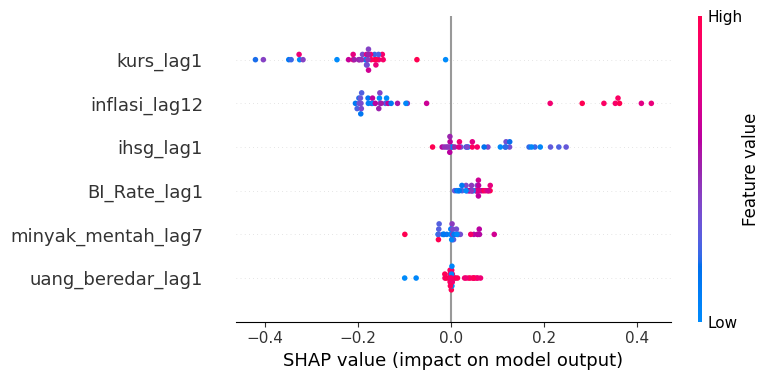

In [ ]:
plt.figure(figsize=(8,6))

shap.summary_plot(
    shap_values,
    X_test,
    show=False
)

plt.savefig(
    folder+"SHAP_SummaryPlot_Model3_BI.jpeg",
    dpi=600,
    bbox_inches='tight'
)

plt.show()

## Bar Plot (Feature Importance)

In [ ]:
importance = np.abs(shap_values).mean(axis=0)

importance_df = pd.DataFrame({
    "Fitur":X_test.columns,
    "Mean |SHAP|":importance
})

importance_df = importance_df.sort_values(
    by="Mean |SHAP|",
    ascending=False
)

print(importance_df)

#Save Tabel Hasil
importance_df.to_csv(
    folder+"SHAP_FeatureImportance_Model3_BI.csv",
    index=False
)

                Fitur  Mean |SHAP|
1           kurs_lag1     0.208320
0       inflasi_lag12     0.200360
2           ihsg_lag1     0.074503
5        BI_Rate_lag1     0.048966
4  minyak_mentah_lag7     0.022884
3   uang_beredar_lag1     0.020500


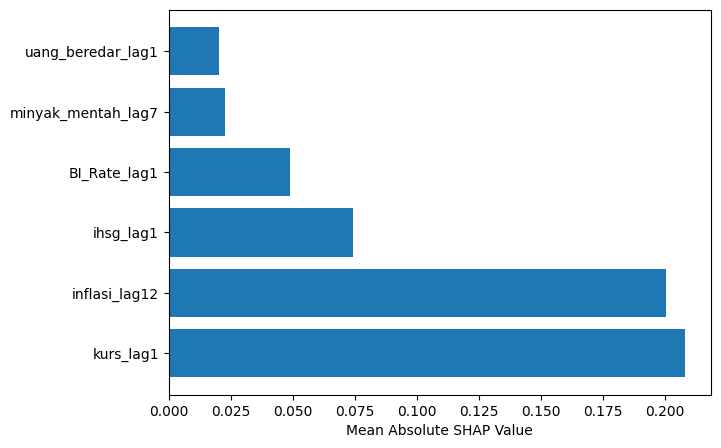

In [ ]:
#Save Grafik Hasil
plt.figure(figsize=(7,5))

plt.barh(
    importance_df["Fitur"],
    importance_df["Mean |SHAP|"]
)

plt.xlabel("Mean Absolute SHAP Value")

plt.savefig(
    folder+"SHAP_BarPlot_Model3_BI.jpeg",
    dpi=600,
    bbox_inches='tight'
)

plt.show()

## Dependence Plot

### Inflasi_lag1 Dependence Plot



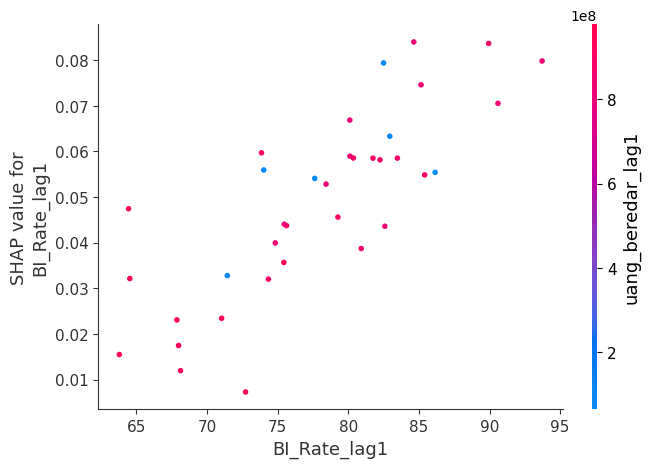

In [ ]:
shap.dependence_plot(
    "BI_Rate_lag1",
    shap_values,
    X_test,
    show=False
)

plt.savefig(
    folder+"Dependence_BI_Rate_lag1.jpeg",
    dpi=600,
    bbox_inches='tight'
)

plt.show()

### Kurs Dependence Plot


In [ ]:
shap.dependence_plot(
    "Kurs_lag1",
    shap_values,
    X_test,
    show=False
)

plt.savefig(
    folder+"Dependence_Kurs_lag1.jpeg",
    dpi=600,
    bbox_inches='tight'
)

plt.show()

## Waterfall Plot Observasi Pertama

In [ ]:
#Explain Observasi Pertama
exp = shap.Explanation(
    values=shap_values[1],
    base_values=explainer.expected_value,
    data=X_test.iloc[1],
    feature_names=X_test.columns
)

print(X_test.iloc[0])

inflasi_lag12         5.600000e-01
kurs_lag1             1.561500e+04
ihsg_lag1             7.020803e+03
uang_beredar_lag1     8.528022e+08
minyak_mentah_lag7    1.227100e+02
BI_Rate_lag1          8.092000e+01
Name: 144, dtype: float64


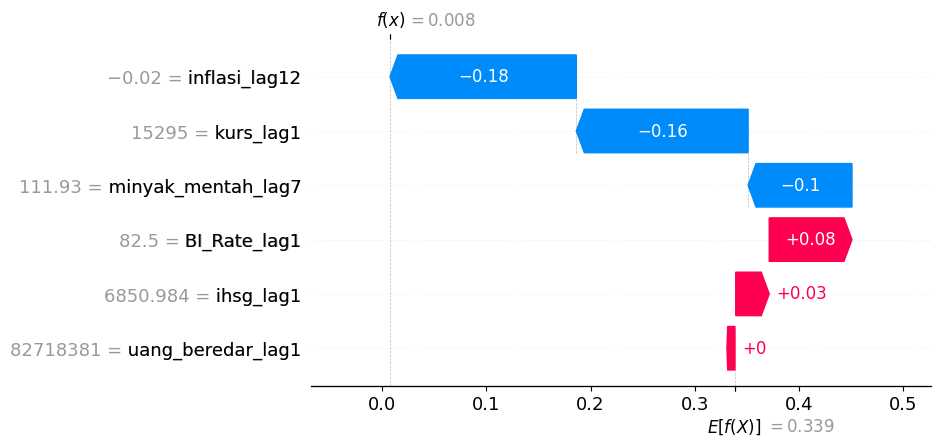

In [ ]:
#Grafik Waterfall Plot
shap.plots.waterfall(
    exp,
    show=False
)

plt.savefig(
    folder+"SHAP_Waterfall_Observasi1.jpeg",
    dpi=600,
    bbox_inches='tight'
)

plt.show()

## Waterfall Plot Looping Cetak 5 Grafik Observasi Pertama

SHAP_Waterfall_Observasi ke-0


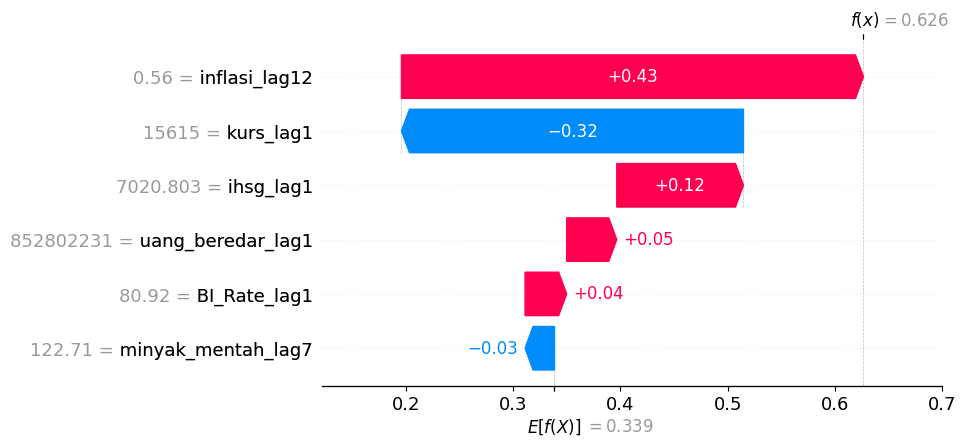

SHAP_Waterfall_Observasi ke-1


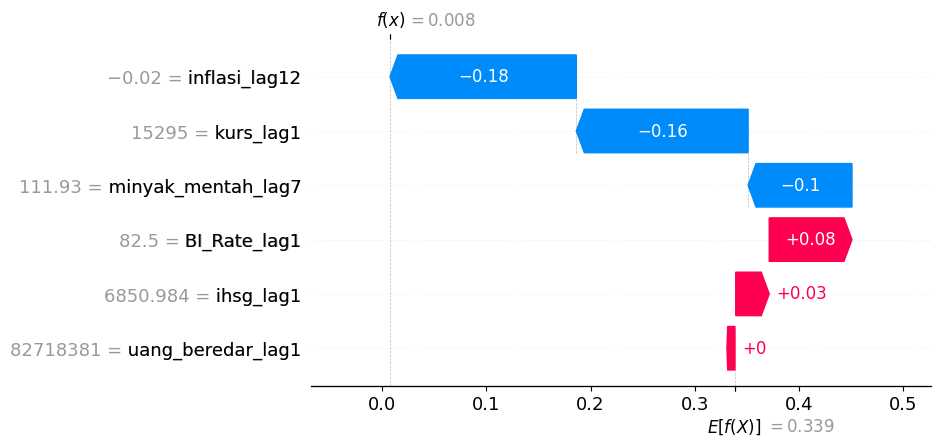

SHAP_Waterfall_Observasi ke-2


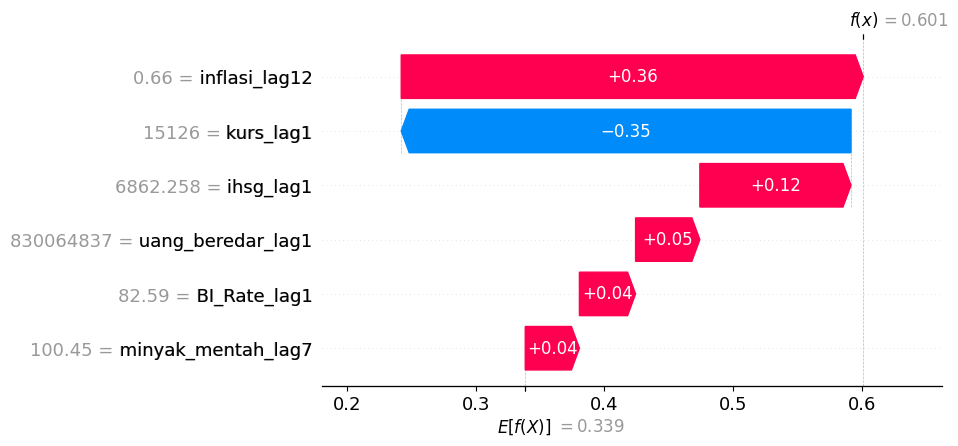

SHAP_Waterfall_Observasi ke-3


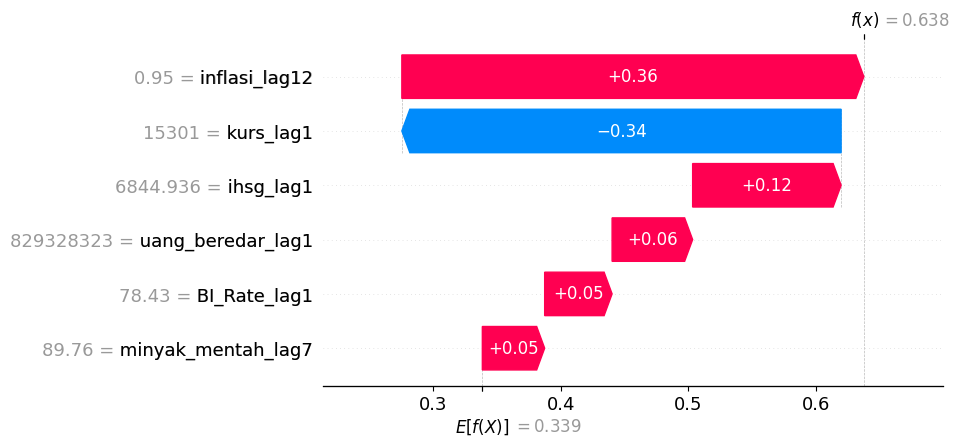

SHAP_Waterfall_Observasi ke-4


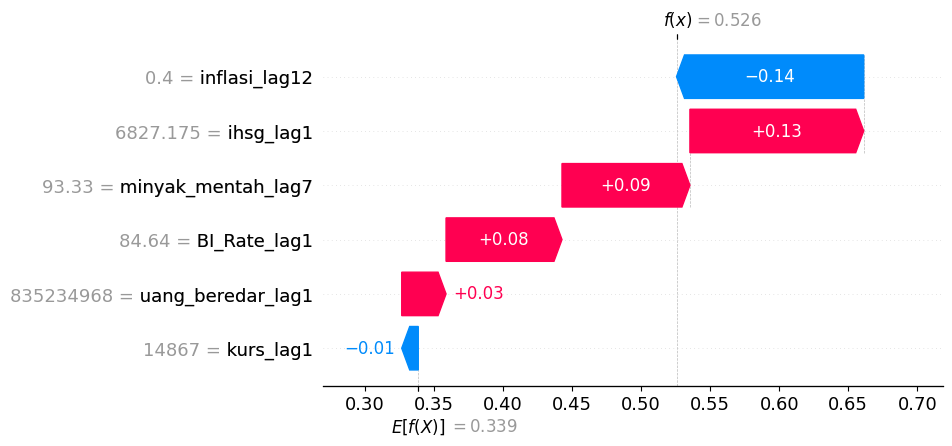

In [ ]:
for i in range(5):
    exp = shap.Explanation(
        values=shap_values[i],
        base_values=explainer.expected_value,
        data=X_test.iloc[i],
        feature_names=X_test.columns
    )

    print(f"SHAP_Waterfall_Observasi ke-{i}")
    # print(X_test.iloc[i])

    shap.plots.waterfall(exp, show=False)
    plt.savefig(
      folder+f"SHAP_Waterfall_Observasi_ke-{i}.jpeg",
      dpi=600,
      bbox_inches='tight'
    )
    plt.show()
    plt.close()

## Menyimpan Prediksi

In [ ]:
hasil = X_test.copy()

hasil["Aktual"] = y_test.values
hasil["Prediksi"] = y_pred.round(2)

print(hasil.head())

hasil.to_csv(
    folder+"Hasil_Prediksi.csv",
    index=False
)

     inflasi_lag12  kurs_lag1    ihsg_lag1  uang_beredar_lag1  \
144           0.56    15615.0  7020.803223        852802231.0   
145          -0.02    15295.0  6850.983887         82718381.0   
146           0.66    15126.0  6862.257812        830064837.0   
147           0.95    15301.0  6844.936035        829328323.0   
148           0.40    14867.0  6827.174805        835234968.0   

     minyak_mentah_lag7  BI_Rate_lag1  Aktual  Prediksi  
144              122.71         80.92    0.34      0.63  
145              111.93         82.50    0.16      0.01  
146              100.45         82.59    0.18      0.60  
147               89.76         78.43    0.33      0.64  
148               93.33         84.64    0.09      0.53  


## Seluruh Hasil Evaluasi

In [ ]:
corr = np.corrcoef(y_test,y_pred)[0,1]
evaluasi = pd.DataFrame({
    "RMSE":[rmse],
    "MAE":[mae],
    "R2":[r2],
    "Correlation":[corr]
})

print(evaluasi)

evaluasi.to_csv(
    folder+"Evaluasi_Model3_BI_Rate_lag1.csv",
    index=False
)

      RMSE       MAE        R2  Correlation
0  0.38275  0.299873  0.105186     0.374538
